<a href="https://colab.research.google.com/github/Benzene-1002/CareerLog/blob/main/DeepLearning_24141129_moroishidai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
text = "hello世界😀"
print(list(text))

print(ord('h'))
print(ord('😀'))

print(chr(104))
print(chr(128512))

ids = [ord(char) for char in list(text)]
print(ids)

class CharTokenizer:
    def encode(self, text):
        return [ord(char) for char in text]

    def decode(self, ids):
        return ''.join([chr(i) for i in ids])

tokenizer = CharTokenizer()
text = "hello世界😀"

ids = tokenizer.encode(text)
print(ids)

decoded = tokenizer.decode(ids)
print(decoded)

['h', 'e', 'l', 'l', 'o', '世', '界', '😀']
104
128512
h
😀
[104, 101, 108, 108, 111, 19990, 30028, 128512]
[104, 101, 108, 108, 111, 19990, 30028, 128512]
hello世界😀


In [ ]:
encoded = 'A'.encode("utf-8")
print(encoded)
print(list(encoded))

encoded = 'あ'.encode("utf-8")
print(encoded)
print(list(encoded))

ids = [65]
decoded = bytes(ids).decode("utf-8")
print(decoded)

class ByteTokenizer:
    def encode(self, text):
        return list(text.encode("utf-8"))

    def decode(self, ids):
        return bytes(ids).decode("utf-8")

tokenizer = ByteTokenizer()
text = "hello世界😀"

ids = tokenizer.encode(text)
print(ids)

decoded = tokenizer.decode(ids)
print(decoded)

b'A'
[65]
b'\xe3\x81\x82'
[227, 129, 130]
A
[104, 101, 108, 108, 111, 228, 184, 150, 231, 149, 140, 240, 159, 152, 128]
hello世界😀


In [ ]:
from collections import defaultdict

def count_pairs(ids):
    counts = defaultdict(int)
    for pair in zip(ids, ids[1:]):
        counts[pair] += 1
    return counts

ids = [1, 2, 3, 1, 2]
counts = count_pairs(ids)
print(counts)

def merge(ids, pair, new_id):
    merged_ids = []
    i = 0

    while i < len(ids):
        if i < len(ids) - 1 and (ids[i], ids[i+1]) == pair:
            merged_ids.append(new_id)
            i += 2
        else:
            merged_ids.append(ids[i])
            i += 1

    return merged_ids

ids = [1, 2, 3, 1, 2]
merged = merge(ids, (1, 2), 4)
print(merged)

def train_bpe(text, vocab_size):
    ids = list(text.encode("utf-8"))

    num_merges = vocab_size - 256
    merge_rules = {}

    for step in range(num_merges):
        counts = count_pairs(ids)

        if not counts:
            break

        best_pair = max(counts, key=counts.get)

        new_id = 256 + step
        merge_rules[best_pair] = new_id

        ids = merge(ids, best_pair, new_id)

    return merge_rules

text = "Hello world! This is BPE training."
merge_rules = train_bpe(text, vocab_size=260)
print(merge_rules)

defaultdict(<class 'int'>, {(1, 2): 2, (2, 3): 1, (3, 1): 1})
[4, 3, 4]
{(105, 115): 256, (256, 32): 257, (105, 110): 258, (72, 101): 259}


In [ ]:
from collections import defaultdict

def count_pairs(ids):
    counts = defaultdict(int)
    for pair in zip(ids, ids[1:]):
        counts[pair] += 1
    return counts

def merge(ids, pair, new_id):
    merged_ids = []
    i = 0

    while i < len(ids):
        if i < len(ids) - 1 and (ids[i], ids[i+1]) == pair:
            merged_ids.append(new_id)
            i += 2
        else:
            merged_ids.append(ids[i])
            i += 1

    return merged_ids

class BPETokenizer:
    def __init__(self, merge_rules):
        self.merge_rules = merge_rules

        self.id_to_bytes = {i: bytes([i]) for i in range(256)}

        for (id1, id2), new_id in merge_rules.items():
            self.id_to_bytes[new_id] = self.id_to_bytes[id1] + self.id_to_bytes[id2]

        self.vocab_size = len(self.id_to_bytes)

    def encode(self, text):
        ids = list(text.encode("utf-8"))

        for merge_pair, new_id in self.merge_rules.items():
            ids = merge(ids, merge_pair, new_id)

        return ids

    def decode(self, ids):
        byte_list = [self.id_to_bytes[i] for i in ids]

        combined_bytes = b"".join(byte_list)

        text = combined_bytes.decode("utf-8", errors="replace")
        return text

merge_rules = {(105, 115): 256, (256, 32): 257, (105, 110): 258, (72, 101): 259}

tokenizer = BPETokenizer(merge_rules)

text = "Hello世界😀"
ids = tokenizer.encode(text)
decoded = tokenizer.decode(ids)

print(ids)
print(decoded)

[259, 108, 108, 111, 228, 184, 150, 231, 149, 140, 240, 159, 152, 128]
Hello世界😀


In [ ]:
from collections import defaultdict
import re

def count_pairs(ids, counts=None):
    if counts is None:
        counts = defaultdict(int)

    for pair in zip(ids, ids[1:]):
        counts[pair] += 1
    return counts

def merge(ids, pair, new_id):
    merged_ids = []
    i = 0
    while i < len(ids):
        if i < len(ids) - 1 and (ids[i], ids[i+1]) == pair:
            merged_ids.append(new_id)
            i += 2
        else:
            merged_ids.append(ids[i])
            i += 1
    return merged_ids

def train_bpe(input_text, vocab_size, end_token="<|endoftext|>"):
    texts = input_text.split(end_token)
    ids_list = [list(text.encode("utf-8")) for text in texts]

    num_merges = vocab_size - 256 - 1
    merge_rules = {}

    for step in range(num_merges):
        counts = defaultdict(int)
        for ids in ids_list:
            counts = count_pairs(ids, counts)

        if not counts:
            break

        best_pair = max(counts, key=counts.get)
        new_id = 256 + step
        merge_rules[best_pair] = new_id

        for i in range(len(ids_list)):
            ids_list[i] = merge(ids_list[i], best_pair, new_id)

    return merge_rules

sample_text = "Hello world!<|endoftext|>This is BPE training."

merge_rules = train_bpe(sample_text, vocab_size=260)
print(merge_rules)


class BPETokenizer:
    def __init__(self, merge_rules, end_token="<|endoftext|>"):
        self.merge_rules = merge_rules
        self.end_token = end_token
        self.end_token_id = 256 + len(merge_rules)

        self.id_to_bytes = {i: bytes([i]) for i in range(256)}
        for (id1, id2), new_id in merge_rules.items():
            self.id_to_bytes[new_id] = self.id_to_bytes[id1] + self.id_to_bytes[id2]
        self.id_to_bytes[self.end_token_id] = self.end_token.encode("utf-8")

        self.vocab_size = len(self.id_to_bytes)

    def _encode_text(self, text):
        ids = list(text.encode("utf-8"))
        for merge_pair, new_id in self.merge_rules.items():
            ids = merge(ids, merge_pair, new_id)
        return ids

    def encode(self, input_text):
        pattern = '(' + re.escape(self.end_token) + ')'
        texts = re.split(pattern, input_text)
        all_ids = []

        for text in texts:
            if text == self.end_token:
                all_ids.append(self.end_token_id)
            else:
                ids = self._encode_text(text)
                all_ids.extend(ids)

        return all_ids

    def decode(self, ids):
        byte_list = [self.id_to_bytes[i] for i in ids]
        text_bytes = b"".join(byte_list)
        text = text_bytes.decode("utf-8", errors="replace")
        return text

tokenizer = BPETokenizer(merge_rules)

text = "Hello world!<|endoftext|>"
ids = tokenizer.encode(text)
decoded = tokenizer.decode(ids)

print(ids)
print(decoded)

{(105, 115): 256, (256, 32): 257, (105, 110): 258}
[72, 101, 108, 108, 111, 32, 119, 111, 114, 108, 100, 33, 259]
Hello world!<|endoftext|>


In [ ]:
from collections import defaultdict
import regex as re
from tqdm import tqdm


def pretokenize(text):
    pattern = r"""'(?:[sdmt]|ll|ve|re)| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+"""
    return re.findall(pattern, text)

def count_pairs(ids, counts=None):
    if counts is None:
        counts = defaultdict(int)

    for pair in zip(ids, ids[1:]):
        counts[pair] += 1
    return counts

def merge(ids, pair, new_id):
    merged_ids = []
    i = 0
    while i < len(ids):
        if i < len(ids) - 1 and (ids[i], ids[i+1]) == pair:
            merged_ids.append(new_id)
            i += 2
        else:
            merged_ids.append(ids[i])
            i += 1
    return merged_ids

def train_bpe(input_text, vocab_size, end_token="<|endoftext|>"):
    texts = input_text.split(end_token)

    ids_list = []
    for text in texts:
        for pretoken in pretokenize(text):
            ids_list.append(list(pretoken.encode("utf-8")))

    num_merges = vocab_size - 256 - 1
    merge_rules = {}

    for step in tqdm(range(num_merges), desc="Training BPE"):
        counts = defaultdict(int)
        for ids in ids_list:
            counts = count_pairs(ids, counts)

        if not counts:
            break

        best_pair = max(counts, key=counts.get)

        new_id = 256 + step
        merge_rules[best_pair] = new_id

        for i in range(len(ids_list)):
            ids_list[i] = merge(ids_list[i], best_pair, new_id)

    return merge_rules


class BPETokenizer:
    def __init__(self, merge_rules, end_token="<|endoftext|>"):
        self.merge_rules = merge_rules
        self.end_token = end_token
        self.end_token_id = 256 + len(merge_rules)

        self.id_to_bytes = {i: bytes([i]) for i in range(256)}
        for (id1, id2), new_id in merge_rules.items():
            self.id_to_bytes[new_id] = self.id_to_bytes[id1] + self.id_to_bytes[id2]
        self.id_to_bytes[self.end_token_id] = self.end_token.encode("utf-8")

        self.vocab_size = len(self.id_to_bytes)

    def _encode_text(self, text):
        ids = list(text.encode("utf-8"))
        for merge_pair, new_id in self.merge_rules.items():
            ids = merge(ids, merge_pair, new_id)
        return ids

    def encode(self, input_text, show_progress=False):
        pattern = '(' + re.escape(self.end_token) + ')'
        texts = re.split(pattern, input_text)
        all_ids = []

        texts = tqdm(texts, desc="Encoding") if show_progress else texts

        for text in texts:
            if text == self.end_token:
                all_ids.append(self.end_token_id)
            else:
                for pretoken in pretokenize(text):
                    ids = self._encode_text(pretoken)
                    all_ids.extend(ids)

        return all_ids

    def decode(self, ids):
        byte_list = [self.id_to_bytes[i] for i in ids]
        text_bytes = b"".join(byte_list)
        text = text_bytes.decode("utf-8", errors="replace")
        return text

sample_text = "Say hello! Why hello? Just hello.<|endoftext|>Good morning!"

merge_rules = train_bpe(sample_text, vocab_size=270)
tokenizer = BPETokenizer(merge_rules)

text = "Say hello!"
ids = tokenizer.encode(text)
decoded = tokenizer.decode(ids)

print(ids)
print(decoded)

for token_id in ids:
    print(f"{token_id} -> '{tokenizer.decode([token_id])}'")

Training BPE: 100%|██████████| 13/13 [00:00<00:00, 22401.79it/s]

[262, 260, 33]
Say hello!
262 -> 'Say'
260 -> ' hello'
33 -> '!'


In [ ]:
import os, sys

os.chdir('/content/deep-learning-from-scratch-6')
if os.getcwd() not in sys.path:
    sys.path.append(os.getcwd())

import pickle
from codebot.tokenizer import train_bpe

vocab_size = 1000
text = open("codebot/tiny_codes.txt").read()
merge_rules = train_bpe(text, vocab_size)

with open("codebot/merge_rules.pkl", "wb") as f:
    pickle.dump(merge_rules, f)

Training BPE: 100%|██████████| 743/743 [33:49<00:00,  2.73s/it]


In [ ]:
import os, sys
os.chdir('/content/deep-learning-from-scratch-6')
if os.getcwd() not in sys.path:
    sys.path.append(os.getcwd())

from codebot.tokenizer import BPETokenizer

tokenizer = BPETokenizer.load_from("codebot/merge_rules.pkl")

print("最初に学習された10個:")
for token_id in range(256, 266):
    byte_seq = tokenizer.id_to_bytes[token_id]
    text = byte_seq.decode("utf-8")
    print(f"  ID {token_id}: '{text}'")

print("\n最後に学習された10個:")
for token_id in range(990, 1000):
    byte_seq = tokenizer.id_to_bytes[token_id]
    text = byte_seq.decode("utf-8")
    print(f"  ID {token_id}: '{text}'")

sample_text = open("codebot/tiny_codes.txt").read()[:10000]

byte_count = len(sample_text.encode("utf-8"))
ids = tokenizer.encode(sample_text)
ids_count = len(ids)
compression_ratio = byte_count / ids_count

print("\n=== 圧縮効率 ===")
print(f"バイト数: {byte_count:,}")
print(f"トークン数: {ids_count:,}")
print(f"圧縮率: {compression_ratio:.2f}倍（平均 {compression_ratio:.2f} バイト/トークン）")

最初に学習された10個:
  ID 256: '  '
  ID 257: '    '
  ID 258: 'in'
  ID 259: '   '
  ID 260: 're'
  ID 261: 'or'
  ID 262: ' ='
  ID 263: 'st'
  ID 264: 'te'
  ID 265: '
   '

最後に学習された10個:
  ID 990: ' '''
  ID 991: 'Error'
  ID 992: 'atter'
  ID 993: 'St'
  ID 994: 'thod'
  ID 995: 'cle'
  ID 996: ' on'
  ID 997: ' R'
  ID 998: 'ery'
  ID 999: '<|endoftext|>'

=== 圧縮効率 ===
バイト数: 10,000
トークン数: 4,709
圧縮率: 2.12倍（平均 2.12 バイト/トークン）


In [ ]:
import os, sys
os.chdir('/content/deep-learning-from-scratch-6')
if os.getcwd() not in sys.path:
    sys.path.append(os.getcwd())

import numpy as np
from codebot.tokenizer import BPETokenizer

tokenizer = BPETokenizer.load_from("codebot/merge_rules.pkl")

text = open("codebot/tiny_codes.txt").read()
ids = tokenizer.encode(text, show_progress=True)

ids_array = np.array(ids, dtype=np.uint16)
ids_array.tofile("codebot/tiny_codes.bin")

print(f"トークンID数: {len(ids_array)}")
print(f"最初の20個のトークンID: {ids_array[:20]}")

Encoding: 100%|██████████| 43671/43671 [11:35<00:00, 62.83it/s]


トークンID数: 2677398
最初の20個のトークンID: [116 528 821 262 544  10 119 717 660  58 265 268 528 107 262 595 338  69
 670 273]


In [1]:
import numpy as np

d = {
    'apple': 100,
    'banana': 200,
    'cherry': 300,
    'durian': 400
}

query = 'banana'
print(d[query])

movie_preferences = {
    (8, 2, 3): 85,
    (3, 9, 1): 70,
    (1, 2, 9): 60,
    (5, 5, 5): 75,
    (7, 6, 2): 80,
    (2, 7, 6): 65,
    (9, 1, 1): 90,
}

new_movie = (6, 4, 5)

def soft_dictionary(query, dictionary):
    similarity = []
    for key in dictionary:
        s = np.dot(query, key)
        similarity.append(s)

    exp_similarity = np.exp(similarity)
    weights = exp_similarity / np.sum(exp_similarity)

    result = 0
    for weight, value in zip(weights, dictionary.values()):
        result += weight * value

    return result, weights


predicted_rating, weights = soft_dictionary(new_movie, movie_preferences)

print(f"新しい映画 {new_movie} の予測評価: {predicted_rating:.2f} 点")
print("\n各映画の重み:")
for key, weight in zip(movie_preferences.keys(), weights):
    print(f"映画 {key}: {weight*100:.2f}%")

200
新しい映画 (6, 4, 5) の予測評価: 78.66 点

各映画の重み:
映画 (8, 2, 3): 0.49%
映画 (3, 9, 1): 0.00%
映画 (1, 2, 9): 0.00%
映画 (5, 5, 5): 26.71%
映画 (7, 6, 2): 72.62%
映画 (2, 7, 6): 0.18%
映画 (9, 1, 1): 0.00%


In [2]:
import torch
import torch.nn.functional as F

K = torch.tensor([
    [8, 2, 3],
    [3, 9, 1],
    [1, 2, 9],
    [5, 5, 5],
    [7, 6, 2],
    [2, 7, 6],
    [9, 1, 1],
], dtype=torch.float32)

V = torch.tensor([
    [85],
    [70],
    [60],
    [75],
    [80],
    [65],
    [90]
], dtype=torch.float32)

Q = torch.tensor([
    [6, 4, 5],
    [2, 8, 3],
    [4, 3, 7],
], dtype=torch.float32)

def attention(Q, K, V):
    similarity = torch.matmul(Q, K.t())
    weights = F.softmax(similarity, dim=1)
    output = torch.matmul(weights, V)
    return output, weights

predicted_ratings, weights = attention(Q, K, V)

for movie, rating in zip(Q, predicted_ratings):
    print(f"映画 {movie.numpy()} の予測評価: {rating.item():.2f}")

映画 [6. 4. 5.] の予測評価: 78.66
映画 [2. 8. 3.] の予測評価: 69.76
映画 [4. 3. 7.] の予測評価: 61.20


tensor([0.0000e+00, 3.7835e-44, 1.0000e+00])
dot product: 0.9024623608064816
scaled dot product: 0.2853836562721152


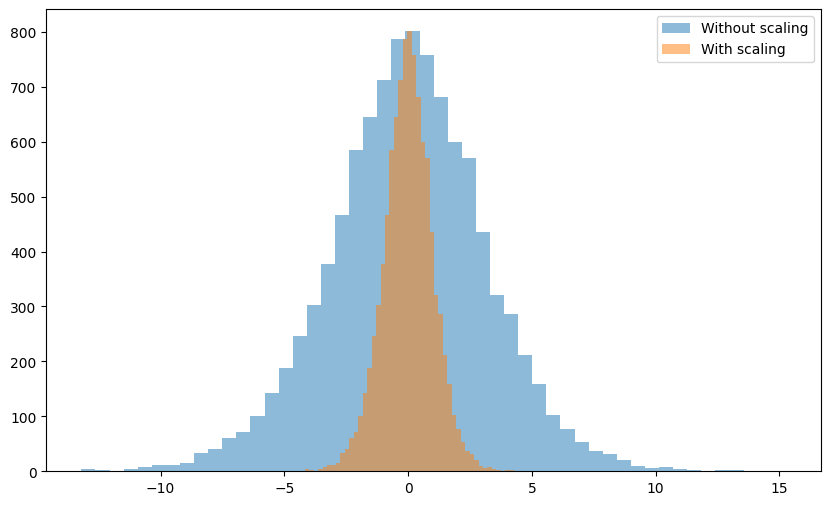

Variances without scaling: 9.987737261493455
Variances with scaling: 0.9987737261493453


In [3]:
import torch
import torch.nn.functional as F

x = torch.tensor([100.0, 200.0, 300.0])
y = F.softmax(x, dim=0)
print(y)


import numpy as np
import matplotlib.pyplot as plt

d = 10

q = np.random.randn(d)
k = np.random.randn(d)

dot_product = np.dot(q, k)
scaled_dot_product = dot_product / np.sqrt(d)

print('dot product:', dot_product)
print('scaled dot product:', scaled_dot_product)


d = 10
num_samples = 10000

dot_products = []
scaled_dot_products = []

for _ in range(num_samples):
    q = np.random.randn(d)
    k = np.random.randn(d)

    dot_product = np.dot(q, k)
    scaled_dot_product = dot_product / np.sqrt(d)

    dot_products.append(dot_product)
    scaled_dot_products.append(scaled_dot_product)


plt.figure(figsize=(10, 6))
plt.hist(dot_products, bins=50, alpha=0.5, label='Without scaling')
plt.hist(scaled_dot_products, bins=50, alpha=0.5, label='With scaling')
plt.legend()
plt.show()

print("Variances without scaling:", np.var(dot_products))
print("Variances with scaling:", np.var(scaled_dot_products))

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Attention(nn.Module):
    def __init__(self, embed_dim, key_dim):
        super().__init__()
        self.W_q = nn.Linear(embed_dim, key_dim, bias=False)
        self.W_k = nn.Linear(embed_dim, key_dim, bias=False)
        self.W_v = nn.Linear(embed_dim, embed_dim, bias=False)

        self.key_dim = key_dim

    def forward(self, x):
        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)

        K_t = K.transpose(-2, -1)
        scores = torch.matmul(Q, K_t)
        scores = scores / (self.key_dim ** 0.5)

        B, C, E = x.shape
        mask = torch.tril(torch.ones(C, C, device=scores.device))
        scores = scores.masked_fill(mask == 0, float('-inf'))
        weights = F.softmax(scores, dim=-1)

        output = torch.matmul(weights, V)
        return output

attention = Attention(embed_dim=256, key_dim=64)
x = torch.randn(2, 5, 256)
y = attention(x)

print("入力形状:", x.shape)
print("出力形状:", y.shape)

入力形状: torch.Size([2, 5, 256])
出力形状: torch.Size([2, 5, 256])


In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Attention(nn.Module):
    def __init__(self, embed_dim, key_dim):
        super().__init__()
        self.W_q = nn.Linear(embed_dim, key_dim, bias=False)
        self.W_k = nn.Linear(embed_dim, key_dim, bias=False)
        self.W_v = nn.Linear(embed_dim, key_dim, bias=False)
        self.W_o = nn.Linear(key_dim, embed_dim, bias=False)
        self.key_dim = key_dim

    def forward(self, x):
        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)

        K_t = K.transpose(-2, -1)
        scores = torch.matmul(Q, K_t)
        scores = scores / (self.key_dim ** 0.5)

        B, C, E = x.shape
        mask = torch.tril(torch.ones(C, C, device=scores.device))
        scores = scores.masked_fill(mask == 0, float('-inf'))

        weights = F.softmax(scores, dim=-1)
        hidden = torch.matmul(weights, V)

        output = self.W_o(hidden)

        return output

attention = Attention(embed_dim=256, key_dim=64)
x = torch.randn(2, 5, 256)
y = attention(x)

print("入力形状:", x.shape)
print("出力形状:", y.shape)

入力形状: torch.Size([2, 5, 256])
出力形状: torch.Size([2, 5, 256])


In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

B = 2
C = 4
E = 16
H = 3
D = 8

x = torch.randn(B, C, E)

W_q = nn.Linear(E, H*D, bias=False)
W_k = nn.Linear(E, H*D, bias=False)
W_v = nn.Linear(E, H*D, bias=False)

Q = W_q(x)
K = W_k(x)
V = W_v(x)

Q = Q.view(B, C, H, D).transpose(1, 2)
K = K.view(B, C, H, D).transpose(1, 2)
V = V.view(B, C, H, D).transpose(1, 2)

scores = torch.matmul(Q, K.transpose(-2, -1))
scores = scores / (D ** 0.5)

mask = torch.tril(torch.ones(C, C, device=scores.device))
scores = scores.masked_fill(mask == 0, float('-inf'))

weights = F.softmax(scores, dim=-1)
hidden = torch.matmul(weights, V)

hidden = hidden.transpose(1, 2)
hidden = hidden.contiguous().view(B, C, H*D)

W_o = nn.Linear(H*D, E, bias=False)
output = W_o(hidden)


class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, n_head, head_dim, dropout_rate=0.1):
        super().__init__()
        self.n_head = n_head
        self.head_dim = head_dim
        E, H, D = embed_dim, n_head, head_dim

        self.W_q = nn.Linear(E, H*D, bias=False)
        self.W_k = nn.Linear(E, H*D, bias=False)
        self.W_v = nn.Linear(E, H*D, bias=False)
        self.W_o = nn.Linear(H*D, E, bias=False)

        self.attention_dropout = nn.Dropout(dropout_rate)
        self.output_dropout = nn.Dropout(dropout_rate)

    def forward(self, x):
        B, C, E = x.shape
        H, D = self.n_head, self.head_dim

        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)

        Q = Q.view(B, C, H, D).transpose(1, 2)
        K = K.view(B, C, H, D).transpose(1, 2)
        V = V.view(B, C, H, D).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1))
        scores = scores / (D ** 0.5)

        mask = torch.tril(torch.ones(C, C, device=scores.device))
        scores = scores.masked_fill(mask == 0, float('-inf'))

        weights = F.softmax(scores, dim=-1)
        weights = self.attention_dropout(weights)
        hidden = torch.matmul(weights, V)

        hidden = hidden.transpose(1, 2).contiguous()
        hidden = hidden.view(B, C, H * D)
        output = self.W_o(hidden)
        output = self.output_dropout(output)

        return output

embed_dim = 512
n_head = 8
head_dim = 64

mha = MultiHeadAttention(embed_dim, n_head, head_dim)

batch_size = 2
context_len = 10
x = torch.randn(batch_size, context_len, embed_dim)

output = mha(x)
print(f"入力形状: {x.shape}")
print(f"出力形状: {output.shape}")

入力形状: torch.Size([2, 10, 512])
出力形状: torch.Size([2, 10, 512])


In [15]:
import torch
import torch.nn as nn


class LayerNorm(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(embed_dim))
        self.beta = nn.Parameter(torch.zeros(embed_dim))
        self.eps = 1e-5

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.gamma * norm_x + self.beta


class GELU(nn.Module):
    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) *
            (x + 0.044715 * torch.pow(x, 3))
        ))

class FFN(nn.Module):
    def __init__(self, x_dim, hidden_dim=None, dropout_rate=0.1):
        super().__init__()
        if hidden_dim is None:
            hidden_dim = int(4 * x_dim)

        self.layers = nn.Sequential(
            nn.Linear(x_dim, hidden_dim),
            GELU(),
            nn.Linear(hidden_dim, x_dim),
            nn.Dropout(dropout_rate)
        )

    def forward(self, x):
        return self.layers(x)


class Block(nn.Module):
    def __init__(self, embed_dim, n_head, ff_dim=None, dropout_rate=0.1):
        super().__init__()
        head_dim = embed_dim // n_head
        self.norm1 = LayerNorm(embed_dim)
        self.attn = MultiHeadAttention(embed_dim, n_head, head_dim, dropout_rate)
        self.norm2 = LayerNorm(embed_dim)
        self.ffn = FFN(embed_dim, ff_dim, dropout_rate)

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.ffn(self.norm2(x))
        return x

In [17]:
import torch
import torch.nn as nn


class GPT(nn.Module):
    def __init__(self, vocab_size, max_context_len, embed_dim, n_head, n_layer, ff_dim, dropout_rate):
        super().__init__()
        self.vocab_size = vocab_size
        self.max_context_len = max_context_len
        self.embed_dim = embed_dim
        self.n_head = n_head
        self.n_layer = n_layer
        self.ff_dim = ff_dim
        self.dropout_rate = dropout_rate

        self.embed = nn.Embedding(vocab_size, embed_dim)
        self.pos_embed = nn.Embedding(max_context_len, embed_dim)
        self.dropout = nn.Dropout(dropout_rate)

        self.blocks = nn.ModuleList([
            Block(embed_dim, n_head, ff_dim, dropout_rate)
            for _ in range(n_layer)
        ])

        self.norm = nn.LayerNorm(embed_dim)
        self.unembed = nn.Linear(embed_dim, vocab_size)

        self.embed.weight = self.unembed.weight

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, ids):
        B, C = ids.shape
        device = ids.device

        pos = torch.arange(0, C, dtype=torch.long, device=device)
        emb = self.embed(ids)
        pos_emb = self.pos_embed(pos)
        x = self.dropout(emb + pos_emb)

        for block in self.blocks:
            x = block(x)
        x = self.norm(x)

        logits = self.unembed(x)
        return logits

    def save(self, file_path):
        checkpoint = {
            'model_state_dict': self.state_dict(),
            'vocab_size': self.vocab_size,
            'max_context_len': self.max_context_len,
            'embed_dim': self.embed_dim,
            'n_head': self.n_head,
            'n_layer': self.n_layer,
            'ff_dim': self.ff_dim,
            'dropout_rate': self.dropout_rate,
        }
        torch.save(checkpoint, file_path)

    @classmethod
    def load_from(cls, file_path, device='cpu'):
        checkpoint = torch.load(file_path, map_location=device)

        model = cls(
            vocab_size=checkpoint['vocab_size'],
            max_context_len=checkpoint['max_context_len'],
            embed_dim=checkpoint['embed_dim'],
            n_head=checkpoint['n_head'],
            n_layer=checkpoint['n_layer'],
            ff_dim=checkpoint['ff_dim'],
            dropout_rate=checkpoint['dropout_rate']
        )
        model.load_state_dict(checkpoint['model_state_dict'])
        model.to(device)

        return model


vocab_size = 1000
max_context_len = 256
embed_dim = 384
n_head = 6
n_layer = 6
ff_dim = 4 * embed_dim
dropout_rate = 0.1

model = GPT(vocab_size, max_context_len, embed_dim, n_head,
             n_layer, ff_dim, dropout_rate)

dummy_input = torch.randint(0, vocab_size, (1, max_context_len))
logits = model(dummy_input)
print(f"出力形状: {logits.shape}")

出力形状: torch.Size([1, 256, 1000])


In [18]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-3, 3, 500)

relu = np.maximum(0, x)

gelu = 0.5 * x * (1 + np.tanh(np.sqrt(2 / np.pi) * (x + 0.044715 * x**3)))

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(x, relu, 'b-', linewidth=2, label='ReLU')
ax.plot(x, gelu, 'r-', linewidth=2, label='GELU')

ax.set_xlim(-3, 3)
ax.set_ylim(-0.5, 3.0)
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('f(x)', fontsize=12)

ax.grid(True, linestyle='--', alpha=0.7)
ax.axhline(y=0, color='gray', linewidth=0.5)
ax.axvline(x=0, color='gray', linewidth=0.5)

ax.legend(loc='upper left', fontsize=12)

plt.tight_layout()

plt.savefig('relu_gelu.png', format='png', bbox_inches='tight')
plt.close()